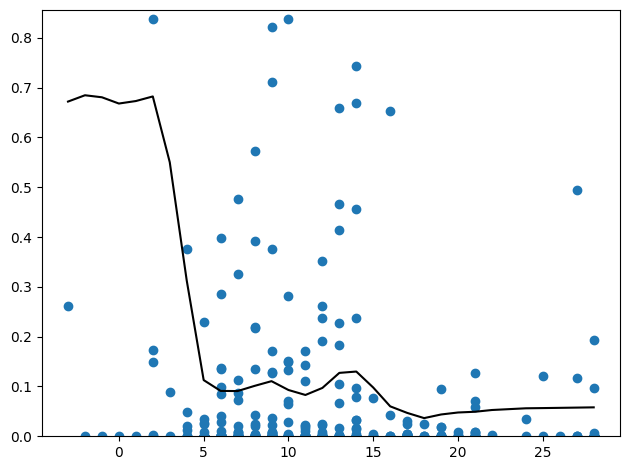

In [ ]:
# Empirical shedding curve (individual samples)
# Direct measurement. Y = N gene / PMMoV (unitless). Smoothed with LOWESS.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# using data from https://journals.asm.org/doi/10.1128/msphere.00132-23

import statsmodels.api as sm
lowess = sm.nonparametric.lowess
shed_data = pd.read_csv('data/empirical_shedding_data.csv')

shed_data['N_conc (gc/mg-dw)'] = shed_data['N_conc (gc/mg-dw)']/shed_data['PMMoV_conc (gc/mg-dw)']
# shed_data = shed_data.dropna(how='any')
curve =lowess(shed_data['N_conc (gc/mg-dw)'],shed_data['Day'],frac=0.25)
curve = np.unique(curve, axis=0)

from scipy import interpolate
kernel_length = curve.shape[0]
maxT = kernel_length-1
f = interpolate.interp1d(range(0,kernel_length), curve[:,1])


# plot raw data in log scaling
fig,ax = plt.subplots()
ax.scatter(shed_data['Day'],shed_data['N_conc (gc/mg-dw)'])
# ax.set_yscale('log')
fig.tight_layout()
fig.savefig('plots/shedding_raw_data_just_data.pdf')
plt.close()

# plot shedding curve, not including outliers
fig,ax = plt.subplots()
ax.scatter(shed_data['Day'],shed_data['N_conc (gc/mg-dw)'])
ax.plot(curve[:,0],curve[:,1],color='black')
ax.set_ylim([0,curve[:,1].max()*1.25])
fig.tight_layout()
# fig.savefig('plots/shedding_raw_data.pdf')
# plt.close()

/var/folders/s2/nry612l527j2xxdsq0_70h6m0000gn/T/ipykernel_31711/1724567032.py:57: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cdf['Sample_Date'] = pd.to_datetime(cdf['Sample_Date'])
(CVXPY) Nov 14 04:11:32 PM: Your problem has 42 variables, 156 constraints, and 0 parameters.
(CVXPY) Nov 14 04:11:32 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Nov 14 04:11:32 PM: DCP verification time: 0.0001 seconds.
(CVXPY) Nov 14 04:11:32 PM: Expression tree has 6 nodes.
(CVXPY) Nov 14 04:11:32 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Nov 14 04:11:32 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Nov 14 04:11:32 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Nov 14 04:11:

                                     CVXPY                                     
                                     v1.9.3                                    
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
-------------------------------------------------------------------------------
                                Numerical solver                               
-------------------------------------------------------------------------------
-------------------------------------------------------------
           Clarabel.rs v0.11.1  -  Clever Acronym                

                   (c) Paul Goulart                          
                University of Oxford, 2022                   
-------------------------------------------------------------

problem:
  variables     = 124
  constraints

(CVXPY) Nov 14 04:11:32 PM: Problem status: optimal
(CVXPY) Nov 14 04:11:32 PM: Optimal value: 3.806e+07
(CVXPY) Nov 14 04:11:32 PM: Compilation took 8.872e-03 seconds
(CVXPY) Nov 14 04:11:32 PM: Solver (including time spent in interface) took 2.393e-02 seconds


  0  +0.0000e+00  -4.3000e+04  4.30e+04  6.61e-01  6.42e-02  1.00e+00  6.26e+06   ------   
  1  +3.1336e+07  +3.1837e+07  1.60e-02  1.12e-01  2.70e-06  5.08e+05  8.78e+05  9.37e-01  
  2  +3.5549e+07  +3.5700e+07  4.24e-03  2.25e-02  4.88e-07  1.52e+05  1.60e+05  8.33e-01  
  3  +3.6718e+07  +3.6791e+07  2.00e-03  9.80e-03  2.08e-07  7.40e+04  5.94e+04  6.92e-01  
  4  +3.7343e+07  +3.7354e+07  3.09e-04  1.96e-03  4.12e-08  1.16e+04  1.98e+04  7.71e-01  
  5  +3.7503e+07  +3.7520e+07  4.64e-04  1.72e-03  3.61e-08  1.75e+04  9.35e+03  7.23e-01  
  6  +3.7697e+07  +3.7703e+07  1.71e-04  7.16e-04  1.50e-08  6.48e+03  4.79e+03  7.62e-01  
  7  +3.7703e+07  +3.7713e+07  2.45e-04  7.72e-04  1.62e-08  9.29e+03  3.47e+03  5.53e-01  
  8  +3.7855e+07  +3.7857e+07  4.82e-05  2.06e-04  4.32e-09  1.84e+03  1.39e+03  8.52e-01  
  9  +3.7892e+07  +3.7894e+07  4.50e-05  1.72e-04  3.59e-09  1.71e+03  9.78e+02  5.08e-01  
 10  +3.7949e+07  +3.7950e+07  1.67e-05  6.59e-05  1.38e-09  6.38e+02  4.91e+02 

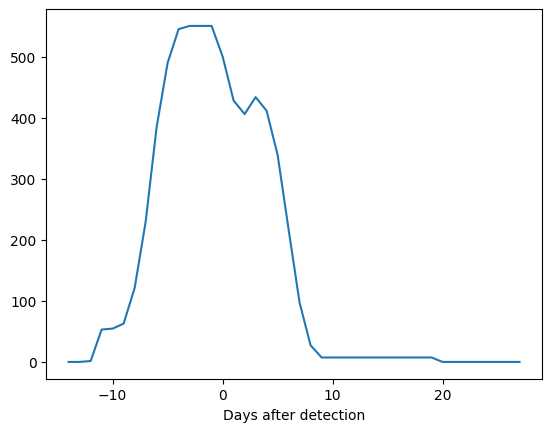

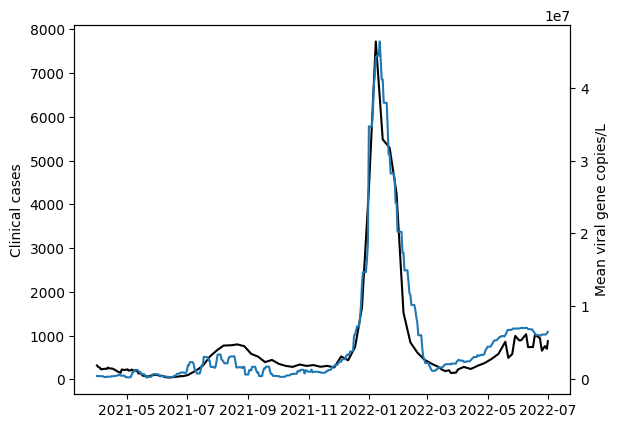

In [28]:
# Inferred shedding kernel via reported cases (Point Loma, N=42, F=14)
# Wastewater gc/L regressed on lagged cases. Includes reporting delay.
# Note: lags = case day minus wastewater day; plot -lags for days after detection.


import numpy as np
# import pymc as pm
# import arviz as az
import pandas as pd 
import pickle
import json
# import requests
from scipy import signal
from datetime import date,timedelta
# import yaml
import copy

import datetime
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

start = pd.to_datetime('2023-01-01')
eval_dates = [start + datetime.timedelta(days=7*j) for j in range(0,52)]


# # option 1: use CDPH data
# cases = pd.read_csv('data/covid19cases_test.csv',index_col=0)
# cases = cases[cases['area'] =='San Diego']
# cases = cases[(cases.index>='2021-06-01') & (cases.index<='2022-07-01')]
# cases.index = pd.to_datetime(cases.index)

# option 2: use SD county data, resolved by catchment. 
cases = pd.read_csv('data/cases.csv',index_col=0)
cases = cases[cases['catchment'] =='PointLoma']
cases = cases[(cases.index>='2021-04-01') & (cases.index<='2022-07-01')]
cases.index = pd.to_datetime(cases.index)
cases = cases.groupby(pd.Grouper(freq='D'))[['new_cases']].sum()
cases['cases'] = cases['new_cases'].rolling(window=7, center=True, min_periods=0).mean()
# cases['positivity'] = cases['cases'].rolling(window=7, center=True, min_periods=0).mean()/cases['total_tests'].rolling(window=7, center=True, min_periods=0).mean()
ww_dict = {'Point Loma':['data/PointLoma_sewage_seqs.csv','data/PointLoma_sewage_qPCR.csv']}
for site, files in zip(ww_dict.keys(),ww_dict.values()):
    df = pd.read_csv(f'{files[0]}')

    df['Date'] = pd.to_datetime(df['Date'])
    df.columns = [dfc.split(' (')[0] for dfc in df.columns]
    df =df.set_index('Date')
    df = df[df.index>='2021-04-01']
    df = df[df.index<='2022-07-01']
    df = df.dropna(axis = 0, how = 'all')
    df = df.fillna(0)
    df = df/100.

    df = df.drop(columns=['Other'])
    df = df[df.columns[df.sum(axis=0) > 0.01]]

    cdf = pd.read_csv(f'{files[1]}')
    cdf['Sample_Date'] = pd.to_datetime(cdf['Sample_Date'])
    cdf =cdf.set_index('Sample_Date')

    cdf = cdf.resample('D').asfreq()
    cdf = cdf.rolling(window=7, center=True, min_periods=0).mean()
    sharedInds = np.sort(list(set(cdf.index) & set(cases.index)))
    cdf = cdf.loc[sharedInds]
    # df = df.loc[sharedInds]
    # df = df[~df.index.duplicated(keep='last')]
    # scaleddf = df.mul(cdf['Mean viral gene copies/L'],axis=0)



minInd = np.max([cdf.index.min(),cases.index.min()])
maxInd = np.min([cdf.index.max(),cases.index.max()])

cdf = cdf[cdf.index>=minInd]
cdf = cdf[cdf.index<=maxInd]

cases = cases[cases.index>=minInd]
cases = cases[cases.index<=maxInd]

cdf = pd.concat([cdf,cases],axis=1)
cdf = cdf.dropna(how='any')

N = 42
F = 14
# first, let's learn the shedding kernel
X = np.array([cdf['cases'].values[(j-F):(j+N-F)] for j in range(F,(cdf.shape[0]-N+F))])#/cdf['Mean viral gene copies/L'].mean()
Y = np.array(cdf['Mean viral gene copies/L'].values[F:(len(cdf['Mean viral gene copies/L'])-N+F)])#/cdf['Mean viral gene copies/L'].mean()

import cvxpy as cp
# least squares problem
x = cp.Variable(N)
cost = cp.norm(X @ x - Y,2)
## add some constraints on the shape of the curve. 
constraints = [x >= 0, x[0]==0,cp.diff(x[0:F])>=0., cp.abs(cp.diff(x)) <= 1000,cp.abs(cp.diff(x,2)) <= 50,cp.diff(x[N-20:N])<=0.]
prob = cp.Problem(cp.Minimize(cost),constraints)
prob.solve(verbose=True,solver=cp.CLARABEL)
lags = np.arange(N) - F
fig,ax = plt.subplots()
ax.plot(lags,x.value)
ax.set_xlabel("Days after detection")
fig.savefig('test_frequentist.pdf')

fig,ax = plt.subplots()
ax.plot(cdf.index,cdf['cases'],color='black')
ax2 = ax.twinx()
ax2.plot(cdf.index,cdf['Mean viral gene copies/L'])
ax.set_ylabel('Clinical cases')
ax2.set_ylabel('Mean viral gene copies/L')
fig.savefig('trajects.pdf')

shed_df = pd.DataFrame(np.array([lags,x.value]).T,columns=['lags','load'])
shed_df.to_csv('inferred_kernel.csv')


# X = np.array([cdf['cases'].values[(j-F):(j+N-F)] for j in range(F,(cdf.shape[0]-N+F))])#/cdf['cases'].mean()
# Y = np.array(cdf['Mean viral gene copies/L'].values[F:(len(cdf['Mean viral gene copies/L'])-N+F)])/cdf['Mean viral gene copies/L'].mean()

# norm = cdf['Mean viral gene copies/L'].mean()

# with pm.Model() as shedding_model:
#     # S = pm.Gamma("S", alpha = 10, beta=0.1, shape=N) 
#     S = pm.HalfFlat("S",shape=N)
#     mu = pm.math.dot(X, S)
#     # Y_obs = pm.LogNormal("Y_obs", mu=mu, observed=Y) #alpha = mu, beta=100, observed=Y)
#     Y_obs = pm.Gamma("Y_obs", alpha = mu/50, beta=50, observed=Y)
#     trace = pm.sample(1000, return_inferencedata=True)


# lags = np.arange(N) - F
# fig,ax = plt.subplots()
# az.plot_hdi(lags, trace.posterior["S"].values, hdi_prob=0.95,ax=ax)
# ax.plot(lags, np.median(trace.posterior["S"].values,axis=(0,1)), color="blue")
# ax.set_xlabel("Days before detection")
# fig.savefig('test_bayesian.pdf')

# plt.close('all')
